1)Εγκατάσταση βιβλιοθηκών

In [1]:
# Εγκατάσταση της βιβλιοθήκης datasets του Hugging Face
# Η βιβλιοθήκη μάς επιτρέπει να φορτώσουμε τις κριτικές ταινιών
!pip install -q datasets

2)Εισαγωγή βιβλιοθηκών

In [2]:
# Εισαγωγή απαραίτητων βιβλιοθηκών
import re
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from collections import Counter
from datasets import load_dataset
from torch.utils.data import DataLoader, TensorDataset

# Καθορισμός τυχαίων τιμών για επαναληψιμότητα
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Επιλογή GPU εάν είναι διαθέσιμη
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Συσκευή:", device)

Συσκευή: cpu


3)Φόρτωση IMDb Dataset

In [3]:
# Φόρτωση του IMDb Dataset
dataset = load_dataset("stanfordnlp/imdb")

# Εμφάνιση των δεδομένων
print(dataset)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


4)Εμφάνιση μιας κριτικής

In [4]:
# Επιλογή της πρώτης κριτικής
review = dataset["train"][0]["text"]

# Εμφάνιση κειμένου
print(review)

# Εμφάνιση χαρακτηρισμού
print("Label:", dataset["train"][0]["label"])

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, eve

5)Tokenization

In [5]:
# Δημιουργία συνάρτησης διαχωρισμού κειμένου σε λέξεις
def tokenize(text):

    # Μετατροπή κεφαλαίων σε μικρά
    text = text.lower()

    # Αφαίρεση συμβόλων αλλαγής γραμμής HTML
    text = re.sub(r"<br\s*/?>", " ", text)

    # Εντοπισμός αγγλικών λέξεων
    words = re.findall(r"[a-z]+(?:'[a-z]+)?", text)

    return words

# Δοκιμή της συνάρτησης
print(tokenize("This Movie Was AMAZING!"))

print(tokenize(dataset["train"][0]["text"]))

['this', 'movie', 'was', 'amazing']
['i', 'rented', 'i', 'am', 'curious', 'yellow', 'from', 'my', 'video', 'store', 'because', 'of', 'all', 'the', 'controversy', 'that', 'surrounded', 'it', 'when', 'it', 'was', 'first', 'released', 'in', 'i', 'also', 'heard', 'that', 'at', 'first', 'it', 'was', 'seized', 'by', 'u', 's', 'customs', 'if', 'it', 'ever', 'tried', 'to', 'enter', 'this', 'country', 'therefore', 'being', 'a', 'fan', 'of', 'films', 'considered', 'controversial', 'i', 'really', 'had', 'to', 'see', 'this', 'for', 'myself', 'the', 'plot', 'is', 'centered', 'around', 'a', 'young', 'swedish', 'drama', 'student', 'named', 'lena', 'who', 'wants', 'to', 'learn', 'everything', 'she', 'can', 'about', 'life', 'in', 'particular', 'she', 'wants', 'to', 'focus', 'her', 'attentions', 'to', 'making', 'some', 'sort', 'of', 'documentary', 'on', 'what', 'the', 'average', 'swede', 'thought', 'about', 'certain', 'political', 'issues', 'such', 'as', 'the', 'vietnam', 'war', 'and', 'race', 'issues',

6)Μέτρηση συχνότητας λέξεων

In [6]:
# Δημιουργία μετρητή λέξεων
word_counts = Counter()

# Επεξεργασία των 25.000 κριτικών εκπαίδευσης
for review in dataset["train"]["text"]:

    # Μέτρηση συχνότητας κάθε λέξης
    word_counts.update(tokenize(review))

# Εμφάνιση των 10 συχνότερων λέξεων
print(word_counts.most_common(10))

[('the', 336757), ('and', 164142), ('a', 163161), ('of', 145865), ('to', 135717), ('is', 107337), ('in', 93977), ('it', 79168), ('i', 77262), ('this', 76004)]


7)Δημιουργία Vocabulary

In [7]:
# Μέγιστο μέγεθος λεξιλογίου
vocab_size = 10000

# Δημιουργία λεξιλογίου με ειδικές τιμές
vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

# Επιλογή των 9.998 συχνότερων λέξεων
most_common_words = word_counts.most_common(vocab_size - 2)

# Αντιστοίχιση κάθε λέξης σε μοναδικό αριθμό
for word, count in most_common_words:
    vocab[word] = len(vocab)

# Εμφάνιση μεγέθους λεξιλογίου
print("Vocabulary size:", len(vocab))

# Δοκιμή αντιστοίχισης
print("good:", vocab.get("good"))
print("excellent:", vocab.get("excellent"))

Vocabulary size: 10000
good: 49
excellent: 317


8)Μετατροπή λέξεων σε αριθμούς

In [8]:
# Δημιουργία συνάρτησης κωδικοποίησης
def encode_review(text):

    # Διαχωρισμός κειμένου σε λέξεις
    words = tokenize(text)

    # Μετατροπή λέξεων σε αριθμούς
    encoded = [vocab.get(word, 1) for word in words]

    return encoded

# Δοκιμή
print(encode_review("good movie"))

[49, 17]


9) Padding και Truncation

In [9]:
 # Μέγιστο μήκος κάθε κριτικής
max_length = 200

# Δημιουργία συνάρτησης Padding
def pad_review(encoded_review):

    # Διατήρηση των πρώτων 200 λέξεων
    encoded_review = encoded_review[:max_length]

    # Υπολογισμός αριθμού μηδενικών
    padding_length = max_length - len(encoded_review)

    # Προσθήκη μηδενικών
    padded_review = encoded_review + [0] * padding_length

    return padded_review

# Δοκιμή
example = pad_review(encode_review("good movie"))

print("Πρώτες 10 θέσεις:", example[:10])
print("Συνολικό μήκος:", len(example))

Πρώτες 10 θέσεις: [49, 17, 0, 0, 0, 0, 0, 0, 0, 0]
Συνολικό μήκος: 200


10)Προετοιμασία Train, Test και unsupervised δεδομένων

In [10]:
# Μετατροπή όλων των κριτικών σε διανύσματα σταθερού μήκους

# και των ετικετών σε αριθμούς κινητής υποδιαστολής

X_train = torch.tensor(
  [pad_review(encode_review(text)) for text in dataset["train"]["text"]],
  dtype=torch.long)

y_train = torch.tensor(dataset["train"]["label"], dtype=torch.float32)



X_test = torch.tensor(

    [pad_review(encode_review(text)) for text in dataset["test"]["text"]],

    dtype=torch.long

)

y_test = torch.tensor(dataset["test"]["label"], dtype=torch.float32)



# Χωρίζουμε τα δεδομένα εκπαίδευσης σε 80% Training και 20% Validation

total = len(X_train)

split = int(total * 0.8)



# Ανακατεύουμε τις θέσεις των δεδομένων

indices = torch.randperm(total)



train_indices = indices[:split]

val_indices = indices[split:]



# Δημιουργούμε τα δύο σύνολα

X_val = X_train[val_indices]

y_val = y_train[val_indices]



X_train = X_train[train_indices]

y_train = y_train[train_indices]



# Δημιουργούμε DataLoader για το Validation

val_loader = DataLoader(

    TensorDataset(X_val, y_val),

    batch_size=64,

    shuffle=False

)

11)Δημιουργία DataLoaders

In [11]:
# Αριθμός κριτικών ανά ομάδα
batch_size = 64

# Δημιουργία ομάδων εκπαίδευσης
train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=batch_size,
    shuffle=True
)

# Δημιουργία ομάδων ελέγχου
test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=batch_size,
    shuffle=False
)

print("Οι DataLoaders είναι έτοιμοι!")

Οι DataLoaders είναι έτοιμοι!


12)Δημιουργία του νευρωνικού δικτύου

In [12]:
# Δημιουργία της κλάσης του RNN
class SentimentRNN(nn.Module):

    # Αρχικοποίηση των επιπέδων
    def __init__(self, vocab_size, embedding_dim, hidden_dim):

        super().__init__()

        # Μετατροπή λέξεων σε διανύσματα
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        # Δημιουργία απλού RNN
        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Τελικό επίπεδο ταξινόμησης
        self.fc = nn.Linear(hidden_dim, 1)

    # Καθορισμός ροής δεδομένων
    def forward(self, x):

        # Υπολογισμός πραγματικού μήκους κάθε κριτικής
        lengths = (x != 0).sum(dim=1).clamp(min=1)

        # Μετατροπή λέξεων σε διανύσματα
        embedded = self.embedding(x)

        # Παράλειψη των θέσεων Padding
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # Επεξεργασία από το RNN
        output, hidden = self.rnn(packed)

        # Υπολογισμός πρόβλεψης
        prediction = self.fc(hidden[-1])

        return prediction.squeeze(1)


# Καθορισμός παραμέτρων
embedding_dim = 64
hidden_dim = 128

# Δημιουργία μοντέλου
model = SentimentRNN(
    vocab_size,
    embedding_dim,
    hidden_dim
).to(device)

# Εμφάνιση αρχιτεκτονικής
print(model)

SentimentRNN(
  (embedding): Embedding(10000, 64, padding_idx=0)
  (rnn): RNN(64, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


13)Εκπαίδευση 5 runs και επιλογή καλύτερων βάρων

In [13]:
import copy

# Αριθμός ανεξάρτητων εκπαιδεύσεων

num_runs = 5

# Αριθμός epochs ανά εκπαίδευση

epochs = 5



# Αρχικές τιμές για την καλύτερη απόδοση

best_accuracy = -1.0

best_weights = None

best_run = None



# Αποθήκευση αποτελεσμάτων

run_results = []



for run in range(num_runs):



    print(f"\n===== RUN {run + 1}/{num_runs} =====")



    # Διαφορετική αρχικοποίηση βαρών σε κάθε Run

    torch.manual_seed(42 + run)



    # Δημιουργούμε νέο RNN

    model = SentimentRNN(

        vocab_size,

        embedding_dim,

        hidden_dim

    ).to(device)



    # Ορίζουμε τη συνάρτηση σφάλματος

    criterion = nn.BCEWithLogitsLoss()



    # Δημιουργούμε νέο Adam Optimizer

    optimizer = torch.optim.Adam(

        model.parameters(),

        lr=0.00005

    )



    run_best_accuracy = -1.0



    for epoch in range(epochs):



        # Εκπαίδευση

        model.train()

        total_loss = 0.0



        for batch_X, batch_y in train_loader:



            batch_X = batch_X.to(device)

            batch_y = batch_y.to(device)



            optimizer.zero_grad()



            outputs = model(batch_X)

            loss = criterion(outputs, batch_y)



            loss.backward()



            # Περιορισμός μεγάλων gradients

            torch.nn.utils.clip_grad_norm_(

                model.parameters(), max_norm=1.0

            )



            optimizer.step()



            total_loss += loss.item()



        # Έλεγχος ακρίβειας στο Validation Dataset

        model.eval()
        correct = 0
        total = 0



        with torch.no_grad():

            for batch_X, batch_y in val_loader:



                batch_X = batch_X.to(device)

                batch_y = batch_y.to(device)



                outputs = model(batch_X)



                # Μετατροπή σε πιθανότητες

                probabilities = torch.sigmoid(outputs)



                # Θετική κριτική αν η πιθανότητα >= 0.5

                predictions = (probabilities >= 0.5).float()



                correct += (predictions == batch_y).sum().item()

                total += batch_y.size(0)



        accuracy = 100 * correct / total

        average_loss = total_loss / len(train_loader)



        print(

            f"Epoch {epoch + 1}/{epochs} | "

            f"Loss: {average_loss:.4f} | "

            f"Validation Accuracy: {accuracy:.2f}%"

        )



        # Καταγράφουμε την καλύτερη απόδοση του Run

        if accuracy > run_best_accuracy:

            run_best_accuracy = accuracy



        # Αποθηκεύουμε τα καλύτερα βάρη και πολώσεις

        # από όλα τα Runs και όλα τα epochs

        if accuracy > best_accuracy:



            best_accuracy = accuracy

            best_run = run + 1



            best_weights = copy.deepcopy(

                model.state_dict()

            )



            # Αποθήκευση σε αρχείο

            torch.save(

                best_weights,

                "best_sentiment_rnn.pth"

            )



    run_results.append(run_best_accuracy)



    print(

        f"Καλύτερη ακρίβεια Run {run + 1}: "

        f"{run_best_accuracy:.2f}%"

    )



# Φορτώνουμε τα καλύτερα βάρη και πολώσεις

model.load_state_dict(best_weights)

model.eval()



print("\n===== ΤΕΛΙΚΑ ΑΠΟΤΕΛΕΣΜΑΤΑ =====")

print("Καλύτερο Run:", best_run)

print(f"Καλύτερο Validation Accuracy: {best_accuracy:.2f}%")

print("Τα καλύτερα βάρη αποθηκεύτηκαν στο best_sentiment_rnn.pth")



===== RUN 1/5 =====
Epoch 1/5 | Loss: 0.6976 | Validation Accuracy: 51.94%
Epoch 2/5 | Loss: 0.6904 | Validation Accuracy: 53.80%
Epoch 3/5 | Loss: 0.6847 | Validation Accuracy: 55.72%
Epoch 4/5 | Loss: 0.6643 | Validation Accuracy: 62.48%
Epoch 5/5 | Loss: 0.6342 | Validation Accuracy: 62.76%
Καλύτερη ακρίβεια Run 1: 62.76%

===== RUN 2/5 =====
Epoch 1/5 | Loss: 0.6961 | Validation Accuracy: 51.62%
Epoch 2/5 | Loss: 0.6886 | Validation Accuracy: 52.80%
Epoch 3/5 | Loss: 0.6826 | Validation Accuracy: 54.08%
Epoch 4/5 | Loss: 0.6649 | Validation Accuracy: 60.10%
Epoch 5/5 | Loss: 0.6467 | Validation Accuracy: 62.08%
Καλύτερη ακρίβεια Run 2: 62.08%

===== RUN 3/5 =====
Epoch 1/5 | Loss: 0.6963 | Validation Accuracy: 51.76%
Epoch 2/5 | Loss: 0.6905 | Validation Accuracy: 52.50%
Epoch 3/5 | Loss: 0.6870 | Validation Accuracy: 52.80%
Epoch 4/5 | Loss: 0.6839 | Validation Accuracy: 53.26%
Epoch 5/5 | Loss: 0.6790 | Validation Accuracy: 55.90%
Καλύτερη ακρίβεια Run 3: 55.90%

===== RUN 4/5 =

14)Αξιολόγηση στο σύνολο ελέγχου (Test Accuracy)

In [14]:
# Απενεργοποίηση λειτουργίας εκπαίδευσης
model.eval()

# Μετρητές σωστών και συνολικών προβλέψεων
correct = 0
total = 0

# Απενεργοποίηση υπολογισμού παραγώγων
with torch.no_grad():

    # Επεξεργασία των δεδομένων ελέγχου
    for batch_X, batch_y in test_loader:

        # Μεταφορά δεδομένων στη συσκευή
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        # Υπολογισμός προβλέψεων
        outputs = model(batch_X)

        # Μετατροπή σε πιθανότητες
        probabilities = torch.sigmoid(outputs)

        # Ταξινόμηση σε 0 ή 1
        predictions = (probabilities >= 0.5).float()

        # Μέτρηση σωστών προβλέψεων
        correct += (predictions == batch_y).sum().item()

        # Μέτρηση συνολικών κριτικών
        total += batch_y.size(0)

# Υπολογισμός ακρίβειας
accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 63.42%


15)Σύγκριση καλύτερου Validation Accuracy των 5 Runs

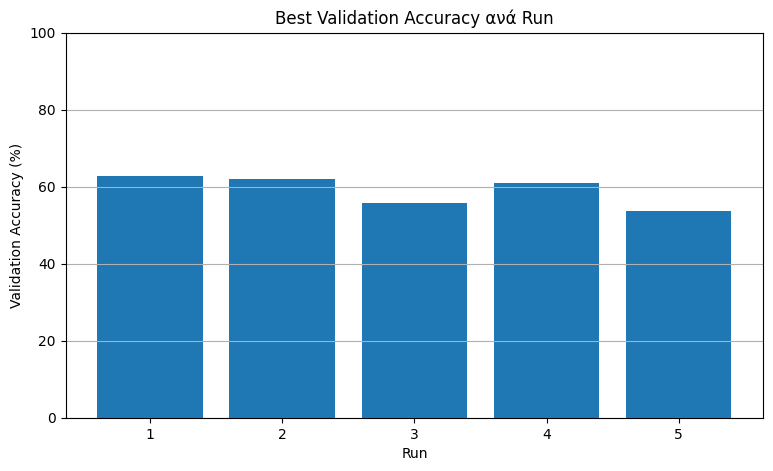

In [15]:

# ΚΕΛΙ 16 — Σύγκριση Accuracy των 5 Runs

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(run_results) + 1),
    run_results
)

plt.xlabel("Run")
plt.ylabel("Validation Accuracy (%)")
plt.title("Best Validation Accuracy ανά Run")
plt.xticks(range(1, len(run_results) + 1))
plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()

16)Αξιολόγηση κριτικής από το unsupervised

In [16]:
#— Ανάλυση συγκεκριμένης IMDb Unsupervised κριτικής

# Επιλέγουμε τον αριθμό της κριτικής, όπως στο Κελί 4
index = 20

# Διαβάζουμε την κριτική από το IMDb
review = dataset["unsupervised"][index]["text"]

# Εμφανίζουμε την κριτική
print("IMDb Review:")
print(review)

# Μετατρέπουμε την κριτική σε αριθμούς
encoded = encode_review(review)

# Προσαρμόζουμε το μήκος της κριτικής
padded = pad_review(encoded)

# Μετατροπή σε Tensor
X_new = torch.tensor([padded], dtype=torch.long).to(device)

# Χρησιμοποιούμε το εκπαιδευμένο RNN
model.eval()

# Πρόβλεψη συναισθήματος
with torch.no_grad():
    output = model(X_new)
    probability = torch.sigmoid(output).item()

# Εμφάνιση αποτελέσματος
print("\n" + "=" * 50)

if probability >= 0.5:
    print("Prediction: POSITIVE")
    print(f"Positive Score: {probability * 100:.2f}%")
else:
    print("Prediction: NEGATIVE")
    print(f"Negative Score: {(1 - probability) * 100:.2f}%")

IMDb Review:
The movie is a bit sloppy from a technical standpoint, but it remains the only movie to make me literally laugh myself sick. The Farrelly brothers owe a huge debt to Robert Klane's mining of the twisted humor genre. For years, this was my video holy grail. Finally, it occurred to me that it probably showed up from time to time on the Fox Movie Channel; so, not having it on my cable system, I started buying the monthly satellite programming guides, and when it came up in the rotation on FMC, I had a friend tape it for me. A simple DVD release will not be adequate. This needs the full Special Edition treatment. And oh, how I hope there are outtakes.

Prediction: POSITIVE
Positive Score: 64.56%


17) Πρόβλεψη νέας κριτικής

In [17]:
# Δημιουργία συνάρτησης πρόβλεψης
def predict_sentiment(text):

    # Έλεγχος για κενή κριτική
    if not tokenize(text):
        print("Παρακαλώ γράψε μια κριτική στα αγγλικά.")
        return

    # Μετατροπή κριτικής σε αριθμούς
    encoded = encode_review(text)

    # Εφαρμογή Padding
    padded = pad_review(encoded)

    # Μετατροπή σε Tensor
    input_tensor = torch.tensor(
        [padded],
        dtype=torch.long
    ).to(device)

    # Απενεργοποίηση λειτουργίας εκπαίδευσης
    model.eval()

    # Υπολογισμός πρόβλεψης
    with torch.no_grad():

        output = model(input_tensor)

        # Υπολογισμός πιθανότητας θετικής κριτικής
        positive_probability = torch.sigmoid(output).item()

    # Υπολογισμός πιθανότητας αρνητικής κριτικής
    negative_probability = 1 - positive_probability

    # Εμφάνιση κριτικής
    print("\nReview:", text)

    # Εμφάνιση χαρακτηρισμού
    if positive_probability >= 0.5:
        print("Prediction: Positive Review")
    else:
        print("Prediction: Negative Review")

    # Εμφάνιση πιθανοτήτων
    print(f"Positive probability: {positive_probability*100:.2f}%")
    print(f"Negative probability: {negative_probability*100:.2f}%")


# Εισαγωγή κριτικής από τον χρήστη
review = input("Write your movie review: ")

# Εμφάνιση πρόβλεψης
predict_sentiment(review)

Write your movie review: lemf

Review: lemf
Prediction: Negative Review
Positive probability: 49.17%
Negative probability: 50.83%
